# Лабораторная работа № 2. Первичный анализ временного ряда
**Тема:** Визуализация, анализ частоты, пропусков и выбросов временного ряда

**Цель:** выполнить первичный анализ синтетического временного ряда, полученного собственным генератором из лабораторной № 1. Проверить качество данных, изучить тренд и сезонность, сравнить восстановление пропусков и обнаружить выбросы

## 1. Импорт библиотек и создание папок
`numpy` нужен для числовых расчётов

`pandas` - для анализа временных данных

`matplotlib` - для графиков

`Path` создаёт папку для результатов

In [39]:
from datetime import datetime, timedelta
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, AutoDateLocator

OUTPUT_DIR = Path('.')
IMAGE_DIR = OUTPUT_DIR / 'images'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
# Единая фиолетовая палитра для графиков
from cycler import cycler
PURPLE = ['#6D28D9', '#A78BFA', '#8B5CF6', '#C4B5FD', '#4C1D95', '#DDD6FE']
plt.rcParams['axes.prop_cycle'] = cycler(color=PURPLE)
plt.rcParams['grid.alpha'] = 0.25
print('Папка графиков:', IMAGE_DIR.resolve())

Папка графиков: /content/images


## 2. Генератор из лабораторной № 1
Ниже приведена исходная функция `generate_time_series` из ***первой лабораторной*** без изменения её логики. Она создаёт значения по формуле: базовый уровень + тренд + сезонность + шум. Шаг между точками **5 минут**. Для анализа выбираются 2016 точек: это ровно 7 дней (7 x 24 x 12)

Чтобы получились заметные и тренд, и повторяемые часовые колебания, используем `trend="slow_up"`, `seasonality="two"`, `volatility="const"`. `seed` позволяет повторить результат

In [40]:
"""Возвращает метки времени, значения ряда и выбранные режимы"""
def generate_time_series(n_points=1000, volatility="random", trend="random",
                         seasonality="random", seed=None):
    if not isinstance(n_points, (int, np.integer)) or isinstance(n_points, (bool, np.bool_)) or n_points <= 0:
        raise ValueError("n_points должно быть положительным целым числом")

    volatility_modes = ("const", "grow", "decay")
    trend_modes = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
    seasonality_modes = ("none", "one", "two")

    for label, option, modes in (
        ("volatility", volatility, volatility_modes),
        ("trend", trend, trend_modes),
        ("seasonality", seasonality, seasonality_modes),
    ):
        if option not in (*modes, "random"):
            raise ValueError(f"Недопустимое значение {label}: {option}. Допустимые: {(*modes, 'random')}")

    rng = np.random.default_rng(seed)
    if volatility == "random":
        volatility = str(rng.choice(volatility_modes))
    if trend == "random":
        trend = str(rng.choice(trend_modes))
    if seasonality == "random":
        seasonality = str(rng.choice(seasonality_modes))

    start_time = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    t = np.arange(n_points)
    position = t / max(n_points - 1, 1)  # от 0 до 1 на протяжении ряда

    # Тренд: изменения за весь наблюдаемый отрезок
    total_changes = {"none": 0, "fast_up": 35, "slow_up": 10,
                     "fast_down": -35, "slow_down": -10}
    trend_values = total_changes[trend] * position

    # Сезонность: периоды 12 точек (1 час) и 72 точки (6 часов)
    seasonal_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        seasonal_values += 7 * np.sin(2 * np.pi * t / 12)
    if seasonality == "two":
        seasonal_values += 4 * np.sin(2 * np.pi * t / 72)

    # Стандартное отклонение задаёт силу шума; дисперсия равна его квадрату
    if volatility == "const":
        sigma = np.full(n_points, 2.0)
    elif volatility == "grow":
        sigma = 1.0 + 6.0 * position
    else:  # decay
        sigma = 7.0 - 6.0 * position

    noise = rng.normal(loc=0.0, scale=sigma, size=n_points)
    values = 100.0 + trend_values + seasonal_values + noise
    modes = {"volatility": volatility, "trend": trend, "seasonality": seasonality}
    return timestamps, values, modes


In [26]:
timestamps, values, modes = generate_time_series(
    n_points=2016, volatility='const', trend='slow_up', seasonality='two', seed=42
)
original = pd.Series(values, index=pd.DatetimeIndex(timestamps), name='value')
assert len(original) == 2016
assert original.index[0].hour == 0 and original.index[0].minute == 0
assert (original.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()
print('Параметры:', modes)
print('Период:', original.index.min(), '—', original.index.max())
print('Число точек:', len(original))
display(original.head().to_frame())

Параметры: {'volatility': 'const', 'trend': 'slow_up', 'seasonality': 'two'}
Период: 2026-11-01 00:00:00 — 2026-11-07 23:55:00
Число точек: 2016


,value
2026-11-01 00:00:00,100.609434
2026-11-01 00:05:00,101.773618
2026-11-01 00:10:00,108.267598
2026-11-01 00:15:00,109.931294
2026-11-01 00:20:00,103.548039


## 3. Создаём учебные пропуски и выбросы
В первом генераторе не было обязательных пропусков и выбросов. Поэтому **после генерации** намеренно повреждаем копию данных: удаляем примерно 4 % значений, добавляем один длинный участок без измерений и 18 сильных отклонений. Исходный ряд сохраняем отдельно, так как он нужен для честной проверки методов восстановления. Временные метки не удаляем: пропущенные значения хранятся как `NaN`

Такая имитация соответствует задаче поиска проблем качества данных, это **не** изменение самого генератора из первой лабораторной.

In [41]:
rng = np.random.default_rng(2026)
damaged = original.copy()
# 18 известных искусственных выбросов на точках, которые не станут пропусками
long_gap = np.arange(480, 505)   # 25 точек подряд = 2 часа 5 минут
possible = np.setdiff1d(np.arange(len(damaged)), long_gap)
outlier_positions = rng.choice(possible, size=18, replace=False)
damaged.iloc[outlier_positions] += rng.choice([-1, 1], size=18) * rng.uniform(25, 40, size=18)

# Пропуски: 60 отдельных позиций и один непрерывный участок
possible_gaps = np.setdiff1d(possible, outlier_positions)
random_gaps = rng.choice(possible_gaps, size=60, replace=False)
missing_positions = np.sort(np.concatenate([long_gap, random_gaps]))
damaged.iloc[missing_positions] = np.nan
print('Известные добавленные пропуски:', len(missing_positions))
print('Известные добавленные выбросы:', len(outlier_positions))
print('Доля пропусков:', f'{damaged.isna().mean():.2%}')
# Сохраняем наблюдения, чтобы показать проверку импорта из CSV
damaged.rename('value').to_csv('series.csv', index_label='timestamp', date_format='%Y-%m-%d %H:%M:%S')

Известные добавленные пропуски: 85
Известные добавленные выбросы: 18
Доля пропусков: 4.22%


## 4. Загрузка, сортировка и проверка регулярности
Загружаем созданный собственным генератором ряд из `series.csv`, преобразуем `timestamp` в даты, сортируем, проверяем повторяющиеся моменты времени и восстанавливаем полную пятиминутную сетку через `date_range`. `asfreq('5min')` задаёт ту же регулярную частоту

In [29]:
df = pd.read_csv('series.csv', parse_dates=['timestamp'])
duplicates = int(df['timestamp'].duplicated().sum())
df = df.sort_values('timestamp').drop_duplicates('timestamp').set_index('timestamp')
full_index = pd.date_range(df.index.min(), df.index.max(), freq='5min')
df = df.reindex(full_index)
df.index.name = 'timestamp'
df = df.asfreq('5min')
print('Дубликатов:', duplicates)
print('Ожидаемых временных меток:', len(full_index))
print('Фактически записанных значений:', int(df['value'].notna().sum()))
print('Пропущенных значений:', int(df['value'].isna().sum()))
print('Частота:', df.index.freq)
assert duplicates == 0 and len(df) == 2016
assert df['value'].isna().sum() == 85

Дубликатов: 0
Ожидаемых временных меток: 2016
Фактически записанных значений: 1931
Пропущенных значений: 85
Частота: <5 * Minutes>


## 5. Основные показатели (EDA)
Смотрим количество наблюдений, среднее, медиану, разброс, минимум и максимум. Из-за искусственных выбросов минимум и максимум могут быть необычно большими по модулю

,Значение
count,1931.000
mean,104.835
std,7.246
min,58.639
25%,100.230
50%,104.715
75%,109.592
max,150.951


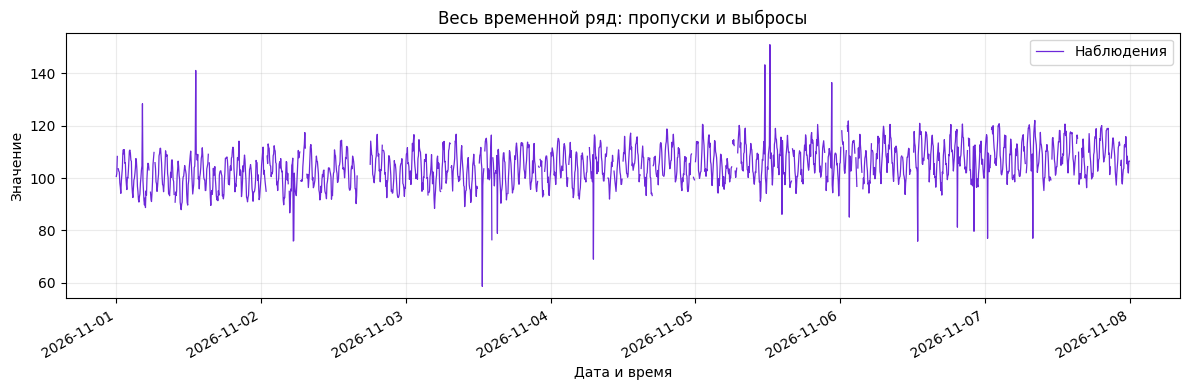

In [30]:
stats = df['value'].describe().to_frame(name='Значение')
display(stats.round(3))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df['value'], lw=0.9, label='Наблюдения')
ax.set(title='Весь временной ряд: пропуски и выбросы', xlabel='Дата и время', ylabel='Значение')
ax.legend()
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_1.png', dpi=150)
plt.show(); plt.close(fig)

## 6. Увеличенный фрагмент и скользящая статистика
Увеличиваем один день, чтобы рассмотреть кратковременные колебания. `rolling(12)` вычисляет среднее и стандартное отклонение по окну 12 пятиминутных точек, то есть за 1 час. Это помогает увидеть локальную динамику и изменение разброса

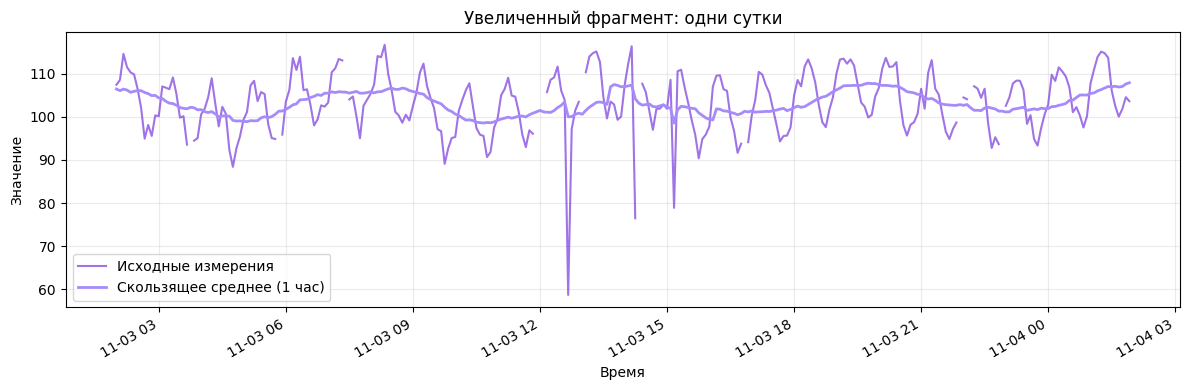

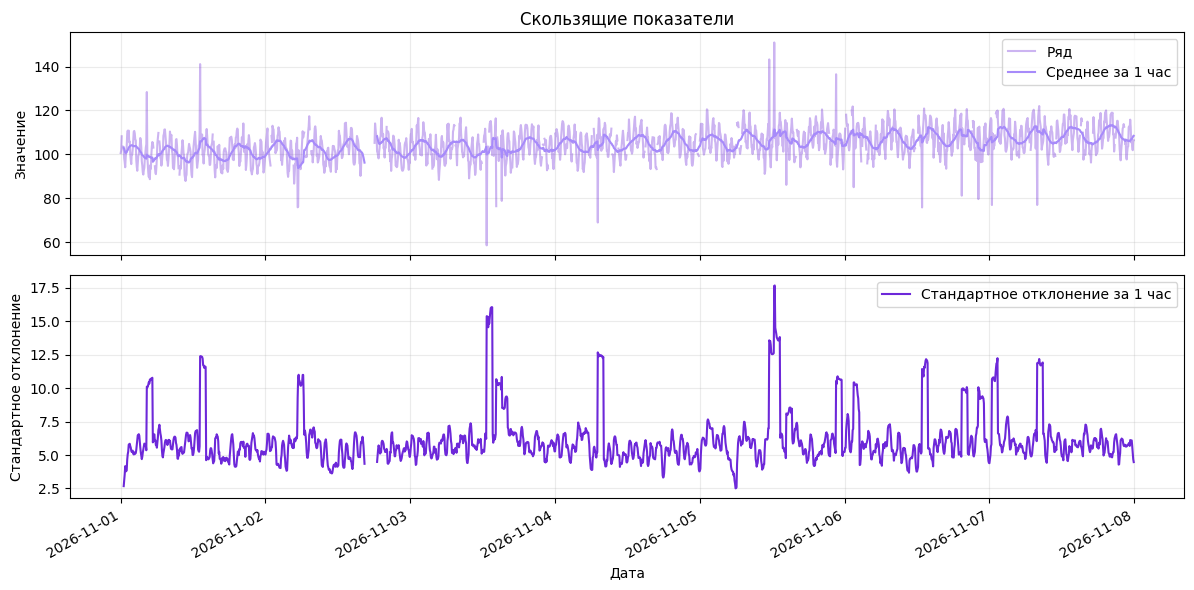

In [31]:
df['rolling_mean'] = df['value'].rolling(window=12, min_periods=6).mean()
df['rolling_std'] = df['value'].rolling(window=12, min_periods=6).std()
fig, ax = plt.subplots(figsize=(12, 4))
fragment = df.iloc[600:888]
ax.plot(fragment.index, fragment['value'], label='Исходные измерения', alpha=0.65)
ax.plot(fragment.index, fragment['rolling_mean'], label='Скользящее среднее (1 час)', linewidth=2)
ax.set(title='Увеличенный фрагмент: одни сутки', xlabel='Время', ylabel='Значение')
ax.legend(); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_2.png', dpi=150)
plt.show(); plt.close(fig)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df.index, df['value'], alpha=0.35, label='Ряд')
axes[0].plot(df.index, df['rolling_mean'], label='Среднее за 1 час')
axes[0].set(ylabel='Значение', title='Скользящие показатели'); axes[0].legend()
axes[1].plot(df.index, df['rolling_std'], label='Стандартное отклонение за 1 час')
axes[1].set(xlabel='Дата', ylabel='Стандартное отклонение'); axes[1].legend()
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_3.png', dpi=150)
plt.show(); plt.close(fig)

## 7. Сезонные подсерии и тепловая карта
Генератор первой лабораторной задаёт периоды 1 час и 6 часов, а не недельную сезонность. Для её изучения усредняем значения по 5-минутному положению внутри часа и по часовому положению внутри шестичасового периода. Также строим часовую `heatmap` «час x день недели», предварительно агрегировав пятиминутные данные в средние за час. Поскольку данных всего 7 дней, карта носит иллюстративный характер и не доказывает недельную сезонность

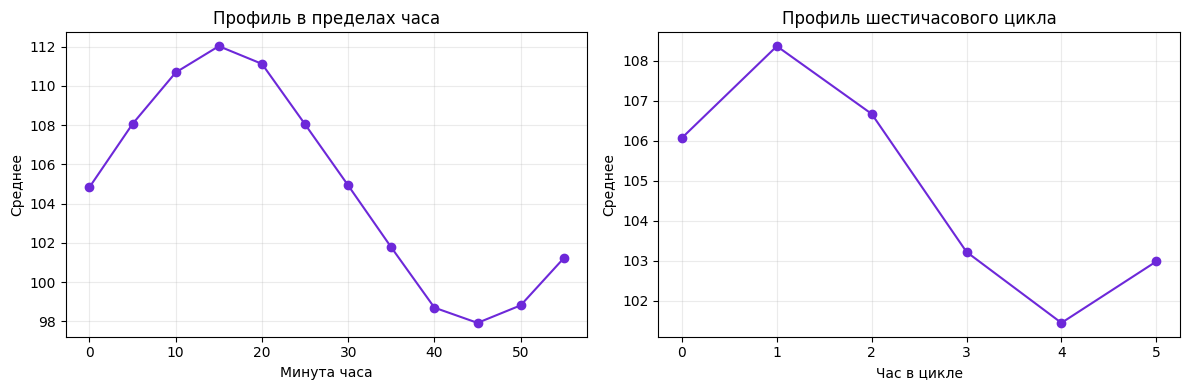

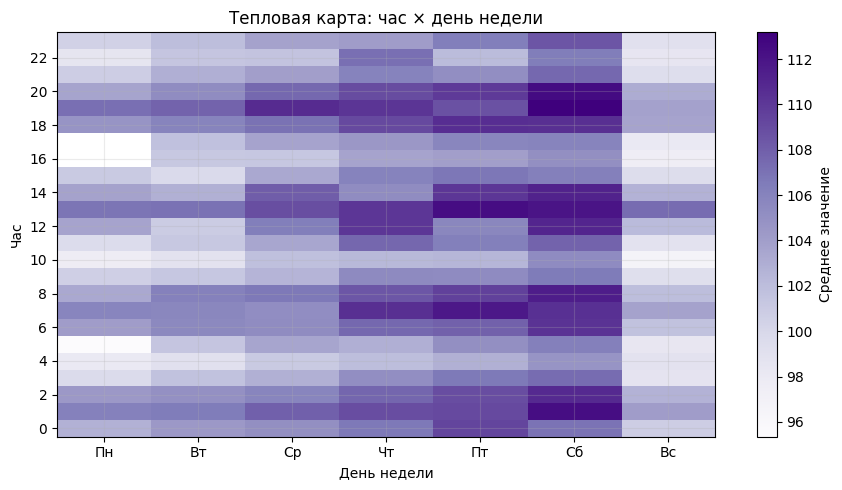

In [32]:
season = df[['value']].copy()
season['slot_in_hour'] = season.index.minute // 5
season['hour_in_cycle'] = season.index.hour % 6
hour_profile = season.groupby('slot_in_hour')['value'].mean()
six_profile = season.groupby('hour_in_cycle')['value'].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hour_profile.index * 5, hour_profile.values, marker='o')
axes[0].set(title='Профиль в пределах часа', xlabel='Минута часа', ylabel='Среднее')
axes[1].plot(six_profile.index, six_profile.values, marker='o')
axes[1].set(title='Профиль шестичасового цикла', xlabel='Час в цикле', ylabel='Среднее')
fig.tight_layout(); fig.savefig(IMAGE_DIR/'lab_image_4.png', dpi=150)
plt.show(); plt.close(fig)
hourly = df['value'].resample('1h').mean().to_frame('value')
hourly['weekday'] = hourly.index.dayofweek
hourly['hour'] = hourly.index.hour
heatmap = hourly.pivot_table(index='hour', columns='weekday', values='value', aggfunc='mean')
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heatmap.reindex(index=range(24), columns=range(7)).values, aspect='auto', origin='lower', cmap='Purples')
ax.set(xticks=range(7), xticklabels=['Пн','Вт','Ср','Чт','Пт','Сб','Вс'], yticks=range(0,24,2), title='Тепловая карта: час × день недели', xlabel='День недели', ylabel='Час')
fig.colorbar(im, ax=ax, label='Среднее значение'); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_5.png', dpi=150)
plt.show();plt.close(fig)

## 8. Подсчёт пропусков и длинных участков
`isna()` показывает, где отсутствует значение, а группировка соседних меток позволяет найти непрерывные участки пропусков. В таблице будут начало, конец и длина каждого такого участка

Всего пропусков: 85
Число участков: 59
Максимальная длина участка (точек): 25


,Начало,Конец,Точек,"Длительность, мин"
0,2026-11-02 16:00:00,2026-11-02 18:00:00,25,125
1,2026-11-02 07:25:00,2026-11-02 07:30:00,2,10
2,2026-11-01 05:30:00,2026-11-01 05:35:00,2,10
3,2026-11-01 06:20:00,2026-11-01 06:20:00,1,5
4,2026-11-01 00:15:00,2026-11-01 00:15:00,1,5
5,2026-11-01 09:40:00,2026-11-01 09:40:00,1,5
6,2026-11-01 15:20:00,2026-11-01 15:20:00,1,5
7,2026-11-02 04:35:00,2026-11-02 04:35:00,1,5
8,2026-11-02 00:55:00,2026-11-02 00:55:00,1,5
9,2026-11-02 06:30:00,2026-11-02 06:30:00,1,5


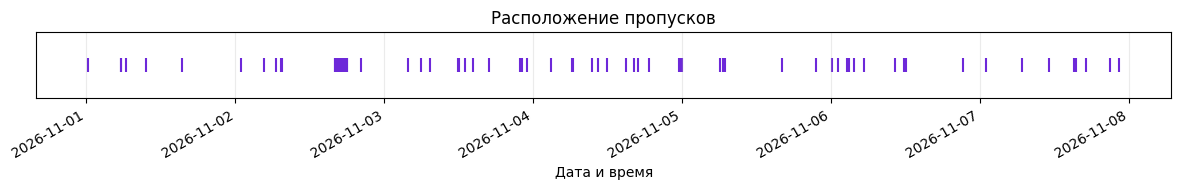

In [33]:
is_missing = df['value'].isna()
block_id = is_missing.ne(is_missing.shift(fill_value=False)).cumsum()
gaps = []
for _, part in df[is_missing].groupby(block_id[is_missing]):
    gaps.append({'Начало': part.index[0], 'Конец': part.index[-1], 'Точек': len(part), 'Длительность, мин': len(part)*5})
gap_table = pd.DataFrame(gaps).sort_values('Точек', ascending=False).reset_index(drop=True)
print('Всего пропусков:', int(is_missing.sum()))
print('Число участков:', len(gap_table))
print('Максимальная длина участка (точек):', int(gap_table['Точек'].max()))
display(gap_table.head(10))
fig, ax = plt.subplots(figsize=(12, 2))
ax.scatter(df.index[is_missing], np.ones(is_missing.sum()), marker='|', s=90)
ax.set(title='Расположение пропусков', xlabel='Дата и время', yticks=[])
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_6.png', dpi=150)
plt.show();plt.close(fig)

## 9. Сравнение методов восстановления (импутации)
Сравниваем четыре подхода: **ffill** (последнее известное значение), **линейная интерполяция**, **медиана** (одно постоянное значение), **сезонный naive** (значение 24 часа назад, если доступно, иначе линейная интерполяция).

***Честная оценка:*** дополнительно скрываем 150 известных значений, не совпадающих с исходными пропусками и выбросами. Затем восстанавливаем их по остальным точкам и считаем MAE - среднюю абсолютную ошибку относительно исходных известных значений. Позиции выбраны с фиксированным `seed`. Результат относится только к нашему синтетическому ряду

,Метод,MAE
3,seasonal_naive,2.5328
1,linear,2.6410
0,ffill,3.7637
2,median,5.6335


Лучший на выбранных скрытых точках метод: seasonal_naive


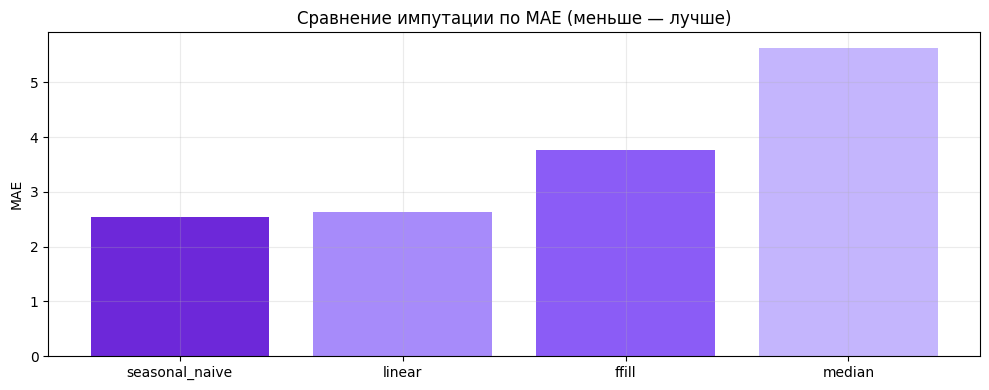

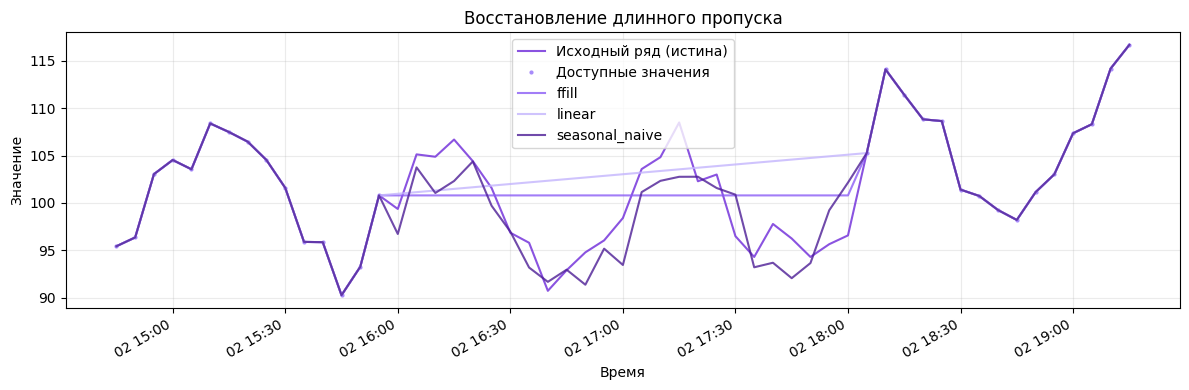

In [42]:
observed = df['value'].copy()
rng_eval = np.random.default_rng(105)
known_positions = np.flatnonzero(observed.notna().values)
known_positions = np.setdiff1d(known_positions, outlier_positions)
hidden_positions = rng_eval.choice(known_positions, size=150, replace=False)
hidden_times = df.index[hidden_positions]
true_hidden = observed.loc[hidden_times].copy()
masked = observed.copy()
masked.loc[hidden_times] = np.nan

def fill_methods(series):
    linear = series.interpolate(method='time', limit_direction='both')
    fill_forward = series.ffill().bfill()
    fill_median = series.fillna(series.median())
    seasonal = series.shift(288)  # 288 * 5 минут = 24 часа
    seasonal = series.where(series.notna(), seasonal)
    seasonal = seasonal.fillna(linear)
    return {'ffill': fill_forward, 'linear': linear, 'median': fill_median, 'seasonal_naive': seasonal}

filled_eval = fill_methods(masked)
mae = {name: float((pred.loc[hidden_times] - true_hidden).abs().mean()) for name, pred in filled_eval.items()}
mae_table = pd.DataFrame({'Метод': list(mae), 'MAE': list(mae.values())}).sort_values('MAE')
display(mae_table.round(4))
print('Лучший на выбранных скрытых точках метод:', mae_table.iloc[0]['Метод'])
filled_real = fill_methods(observed)

# Сохраняем восстановленные версии оригинально пропущенных точек
compare = pd.DataFrame({'original_observed': observed, **filled_real})
compare.to_csv('imputation_results.csv', index_label='timestamp')
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(mae_table['Метод'], mae_table['MAE'], color=PURPLE[:len(mae_table)])
ax.set(title='Сравнение импутации по MAE (меньше — лучше)', ylabel='MAE')
fig.tight_layout(); fig.savefig(IMAGE_DIR/'lab_image_7.png', dpi=150)
plt.show();plt.close(fig)
fig, ax = plt.subplots(figsize=(12,4))
seg = slice(465, 520)
ax.plot(original.index[seg], original.iloc[seg], label='Исходный ряд (истина)', alpha=0.8)
ax.plot(df.index[seg], observed.iloc[seg], 'o', ms=2, label='Доступные значения')
for method in ['ffill', 'linear', 'seasonal_naive']:
    ax.plot(df.index[seg], filled_real[method].iloc[seg], label=method, alpha=0.8)
ax.set(title='Восстановление длинного пропуска', ylabel='Значение', xlabel='Время')
ax.legend(); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_8.png', dpi=150)
plt.show();plt.close(fig)

## 10. Обнаружение выбросов тремя методами
**IQR**: значения за границами Q1 - 1.5 x IQR и Q3 + 1.5 x IQR

**Z-score**: значения, у которых абсолютное отклонение от среднего превышает 3 стандартных отклонения

**Rolling median/MAD**: локально сравниваем измерение с медианой окна из 25 точек и масштабируем через медианное абсолютное отклонение (MAD). Порог - 3.5. На данных с трендом локальный метод обычно удобнее, поскольку учитывает соседние точки

Мы знаем координаты внесённых искусственно выбросов и можем дополнительно оценить, сколько из них обнаружено. Однако результаты разных критериев не обязаны совпадать

,Метод,Отмечено всего,Найдено искусственных из 18,Дополнительных срабатываний
0,IQR,18,18,0
1,Z-score,16,16,0
2,Rolling MAD,12,12,0


,value,IQR,Z-score,Rolling MAD
timestamp,,,,
2026-11-01 04:20:00,128.389995,True,True,True
2026-11-01 13:10:00,141.097917,True,True,True
2026-11-02 05:20:00,75.954797,True,True,False
2026-11-02 05:25:00,76.166703,True,True,False
2026-11-03 12:40:00,58.639257,True,True,True
2026-11-03 14:15:00,76.448857,True,True,True
2026-11-03 15:10:00,78.878927,True,True,False
2026-11-04 07:05:00,69.025470,True,True,True
2026-11-05 11:30:00,143.248142,True,True,True


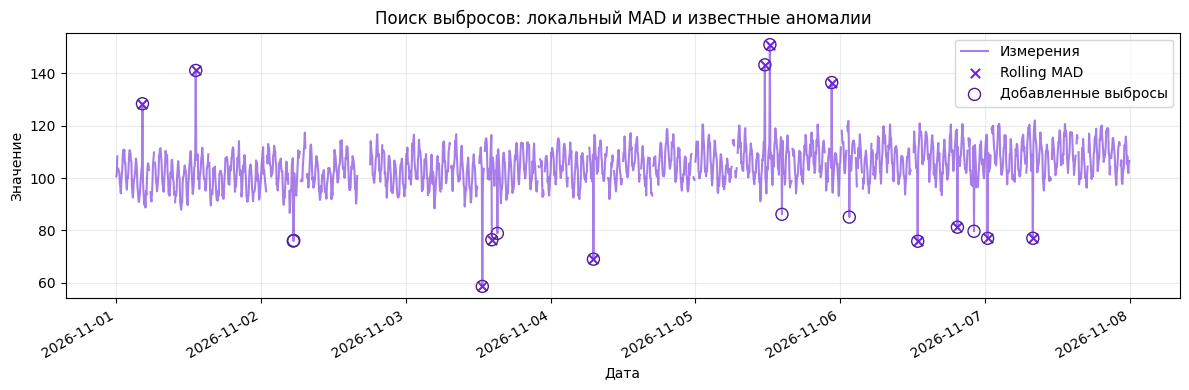

In [35]:
series = df['value']
q1, q3 = series.quantile([0.25, 0.75]); iqr = q3 - q1
out_iqr = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
std = series.std()
z = (series - series.mean()) / std
out_z = z.abs() > 3
rolling_med = series.rolling(25, center=True, min_periods=8).median()
abs_dev = (series - rolling_med).abs()
rolling_mad = abs_dev.rolling(25, center=True, min_periods=8).median()
local_score = abs_dev / (1.4826 * rolling_mad.replace(0, np.nan))
out_mad = local_score > 3.5
outliers = pd.DataFrame({'IQR': out_iqr.fillna(False), 'Z-score': out_z.fillna(False), 'Rolling MAD': out_mad.fillna(False)})
true_outliers = pd.Index(original.index[outlier_positions])
summary = []
for method in outliers.columns:
    flagged = outliers.index[outliers[method]]
    detected = len(flagged.intersection(true_outliers))
    summary.append({'Метод': method, 'Отмечено всего': len(flagged), 'Найдено искусственных из 18': detected, 'Дополнительных срабатываний': len(flagged)-detected})
summary_table = pd.DataFrame(summary)
display(summary_table)
report_outliers = df[['value']].join(outliers)
report_outliers.loc[outliers.any(axis=1)].to_csv('outliers.csv', index_label='timestamp')
display(report_outliers.loc[outliers.any(axis=1)].head(15))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, series.values, alpha=0.6, label='Измерения')
ax.scatter(series.index[out_mad], series[out_mad], marker='x', s=45, label='Rolling MAD')
ax.scatter(true_outliers, series.loc[true_outliers], facecolors='none', edgecolors='#4C1D95', s=75, label='Добавленные выбросы')
ax.set(title='Поиск выбросов: локальный MAD и известные аномалии', xlabel='Дата', ylabel='Значение')
ax.legend(); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR/'lab_image_9.png', dpi=150)
plt.show();plt.close(fig)

## 11. Итоговая проверка и автоматические выводы
Выводим фактические результаты, рассчитанные по данным: наличие заданного тренда и сезонности, число пропусков, максимальную длину непрерывного пропуска, результаты обнаружения выбросов и сравнение импутации

**Интерпретация**: выбросы в этой работе - искусственно внесённые отклонения, то есть ошибки измерения в учебном сценарии. В реальных данных их нельзя удалять без предметной проверки: необычное значение может быть реальным событием

In [38]:
print('ВЫВОДЫ')
print('1. Сформирован ряд длиной', len(df), 'точек с интервалом 5 минут; дубликатов:', duplicates)
print('2. Генератор задал медленный положительный тренд и сезонности 1 час и 6 часов')
print('3. Пропусков:', int(is_missing.sum()), '(', f'{is_missing.mean():.2%}', '); самый длинный участок:', int(gap_table['Точек'].max()), 'точек')
print('4. На скрытых известных данных минимальная MAE у метода:', mae_table.iloc[0]['Метод'], f"({mae_table.iloc[0]['MAE']:.3f})")
print('5. Искусственно добавлено', len(true_outliers), 'выбросов; Rolling MAD обнаружил', int(summary_table.loc[summary_table['Метод']=='Rolling MAD','Найдено искусственных из 18'].iloc[0]), 'из них')
print('6. Перед моделированием необходимо проверять регулярность, обрабатывать пропуски и отдельно исследовать аномалии')
assert len(list(IMAGE_DIR.glob('lab_image_*.png'))) == 9
assert (OUTPUT_DIR/'series.csv').exists()
print('Проверки пройдены. Графиков сохранено:', len(list(IMAGE_DIR.glob('lab_image_*.png'))))

ВЫВОДЫ
1. Сформирован ряд длиной 2016 точек с интервалом 5 минут; дубликатов: 0
2. Генератор задал медленный положительный тренд и сезонности 1 час и 6 часов
3. Пропусков: 85 ( 4.22% ); самый длинный участок: 25 точек
4. На скрытых известных данных минимальная MAE у метода: seasonal_naive (2.533)
5. Искусственно добавлено 18 выбросов; Rolling MAD обнаружил 12 из них
6. Перед моделированием необходимо проверять регулярность, обрабатывать пропуски и отдельно исследовать аномалии
Проверки пройдены. Графиков сохранено: 9
